# Outlook

In this notebook we code the **KL-penalty** version of PPO. Instead of
*clipping* the probability ratio (the version in `07-2`), it keeps the new
policy close to the old one by subtracting a KL-divergence penalty from the
objective.

See the [PPO paper](https://arxiv.org/pdf/1707.06347.pdf) and [these
slides](http://pages.isir.upmc.fr/~sigaud/teach/ps/10_ppo.pdf).

## Setup

**On Colab**: run the installation cell below (generated automatically,
pinned versions). **Locally**: install the environment with `uv sync`, no
need for this cell.

In [1]:
import copy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass, replace
from torch import Tensor
from torch.utils.tensorboard import SummaryWriter
from tqdm.auto import tqdm
from rl_mind.profiles import Profile
from rl_mind.core import Actor, StochasticAction, TensorStruct
from rl_mind.nn import build_mlp
from rl_mind.env import VecEnv
from rl_mind.data import Rollout, minibatches
from rl_mind.collectors import RolloutCollector
from rl_mind.evaluation import Evaluator
from rl_mind.notebook import run_directory, setup_tensorboard, silence_known_warnings


## The `rl_mind` toolkit

The `rl_mind` package ([documentation](https://master-dac.isir.upmc.fr/rl/rl-mind/)),
installed with the practicals, provides the typed helpers used throughout the
RL notebooks. This one uses
`VecEnv`, `Rollout` / `RolloutCollector` (a `[T, B]` on-policy segment),
`minibatches`, `Evaluator`, and the `Actor` base class.

In [2]:
# pygame and tensorboard still use the deprecated `pkg_resources` API
silence_known_warnings()

# PPO with a KL penalty

The overall structure is identical to PPO-clip (`07-2`): collect a rollout,
compute GAE advantages once, then run several epochs of minibatch updates.
The only difference is the policy loss, which maximizes

$$
\max_{\theta}\ \hat{\mathbb{E}}_t\left[ r_t(\theta)\,\hat{A}_t - \beta\,
\operatorname{KL}\!\big[\pi_{\theta_{\text{old}}}(\cdot|s_t)\,\|\,
\pi_\theta(\cdot|s_t)\big] \right]
$$

where $\hat{A}_t$ is the advantage and

$$r_t(\theta) = \frac{\pi_\theta\left(a_t \mid
s_t\right)}{\pi_{\theta_{\text{old}}}\left(a_t \mid s_t\right)}$$

is the probability ratio between the current policy and the policy that
collected the data: a penalty on the KL divergence replaces the clipping.

The ratio itself only needs the log-probabilities stored when the actions
were sampled, but the KL term needs the **full** old distribution at each
state, so we also keep a frozen copy of the policy that collected the
rollout (`old_policy`).

## Definition of the agents

In [3]:
class DiscretePolicy(Actor[StochasticAction]):
    """A stochastic policy for discrete actions, $\\pi(a|s)$"""

    def __init__(self, obs_dim: int, hidden: tuple[int, ...], n_actions: int):
        super().__init__()
        self.model = build_mlp([obs_dim, *hidden, n_actions])

    def dist(self, obs: Tensor) -> torch.distributions.Categorical:
        return torch.distributions.Categorical(logits=self.model(obs))

    def forward(self, obs: Tensor) -> StochasticAction:
        dist = self.dist(obs)
        action = dist.sample()
        return StochasticAction(value=action, log_prob=dist.log_prob(action))

    def act(self, obs: Tensor) -> Tensor:
        return self.model(obs).argmax(-1)

In [4]:
class ValueNetwork(nn.Module):
    """The value network $V(s)$"""

    def __init__(self, obs_dim: int, hidden: tuple[int, ...]):
        super().__init__()
        self.model = build_mlp([obs_dim, *hidden, 1])

    def forward(self, obs: Tensor) -> Tensor:
        return self.model(obs).squeeze(-1)

## GAE and the training data

Unchanged from PPO-clip.

In [5]:
def compute_gae(
    gamma: float, lam: float, rollout: Rollout, values: Tensor, next_values: Tensor
) -> Tensor:
    """Compute the GAE advantages over a rollout (tensors `[T, B]`)"""
    advantages = torch.zeros_like(rollout.reward)
    gae = torch.zeros_like(rollout.reward[0])
    for t in reversed(range(rollout.reward.shape[0])):
        delta = (
            rollout.reward[t]
            + gamma * next_values[t] * (~rollout.terminated[t]).float()
            - values[t]
        )
        gae = delta + gamma * lam * (~rollout.done[t]).float() * gae
        advantages[t] = gae
    return advantages

In [6]:
@dataclass(frozen=True)
class PPOBatch(TensorStruct):
    """The data PPO trains on (all shapes `[N, ...]`)"""

    obs: Tensor
    action: Tensor
    old_log_prob: Tensor
    advantage: Tensor
    returns: Tensor

## Hyper-parameters

In [7]:
@dataclass(frozen=True)
class PPOConfig:
    env_name: str = "CartPole-v1"
    seed: int = 12

    max_updates: int = 100
    n_envs: int = 8
    n_steps: int = 32

    gamma: float = 0.98
    gae_lam: float = 0.8

    #: KL penalty coefficient (beta)
    beta: float = 5.0
    opt_epochs: int = 10
    batch_size: int = 256
    normalize_advantage: bool = False
    entropy_coef: float = 0.0

    actor_hidden: tuple[int, ...] = (64, 64)
    critic_hidden: tuple[int, ...] = (64, 64)
    lr: float = 1e-3

    eval_interval: int = Profile.pick(4_000, fast_test=1_000)
    n_eval_envs: int = 10

## Main training loop

Write the KL-penalty policy loss: the probability ratio $r_t(\theta)$, then
the penalized objective. Useful:

- the ratio is computed from the *difference of log-probabilities*
  (`dist.log_prob(mb.action)` against the stored `mb.old_log_prob`), which
  avoids two exponentials and is numerically better behaved;
- [`torch.distributions.kl_divergence(p, q)`](https://pytorch.org/docs/stable/distributions.html#torch.distributions.kl.kl_divergence)
  computes $\operatorname{KL}[p\,\|\,q]$ per state — pass the **old**
  policy's distribution as $p$ and the current one as $q$.

In [15]:
def run_ppo_penalty(cfg: PPOConfig) -> Evaluator:
    torch.manual_seed(cfg.seed)
    env = VecEnv(cfg.env_name, cfg.n_envs, seed=cfg.seed, same_step_reset=True)

    policy = DiscretePolicy(env.observation_dim, cfg.actor_hidden, env.n_actions)
    critic = ValueNetwork(env.observation_dim, cfg.critic_hidden)
    policy_optimizer = torch.optim.Adam(policy.parameters(), lr=cfg.lr)
    critic_optimizer = torch.optim.Adam(critic.parameters(), lr=cfg.lr)

    collector = RolloutCollector(env, policy)
    run_dir = run_directory(f"ppo-kl-{cfg.env_name}-S{cfg.seed}")
    writer = SummaryWriter(run_dir)
    evaluator = Evaluator(
        VecEnv(cfg.env_name, cfg.n_eval_envs, seed=cfg.seed + 100),
        every=cfg.eval_interval,
        run_dir=run_dir,
        writer=writer,
    )

    pbar = tqdm(range(cfg.max_updates))
    for update in pbar:
        rollout = collector.collect(cfg.n_steps)

        with torch.no_grad():
            values = critic(rollout.obs)
            next_values = critic(rollout.next_obs)
            advantage = compute_gae(
                cfg.gamma, cfg.gae_lam, rollout, values, next_values
            )

        flat = rollout.flatten()
        data = PPOBatch(
            obs=flat.obs,
            action=flat.action.value,
            old_log_prob=flat.action.log_prob,
            advantage=advantage.flatten(),
            returns=(advantage + values).flatten(),
        )

        # Frozen copy of the policy that collected the rollout (for the KL term)
        old_policy = copy.deepcopy(policy)

        for epoch in range(cfg.opt_epochs):
            for mb in minibatches(data, cfg.batch_size):
                advantage_mb = mb.advantage
                if cfg.normalize_advantage:
                    advantage_mb = (advantage_mb - advantage_mb.mean()) / (
                        advantage_mb.std() + 1e-8
                    )

                # Compute the KL-penalty policy loss

                with torch.no_grad(): old_dist = old_policy.dist(mb.obs)

                dist = policy.dist(mb.obs)
                # The probability ratio, from the stored log-probabilities
                ratio = torch.exp(dist.log_prob(mb.action) - old_dist.log_prob(mb.action))
                # KL between the old and the current policy at each state
                
                kl = torch.distributions.kl_divergence(old_dist, dist)
                # maximize  ratio * advantage - beta * kl  (so minimize its negation)
                policy_loss = - (ratio @ advantage_mb - cfg.beta * kl).mean()

                loss = policy_loss - cfg.entropy_coef * dist.entropy().mean()
                policy_optimizer.zero_grad()
                loss.backward()
                policy_optimizer.step()

                critic_loss = F.mse_loss(critic(mb.obs), mb.returns)
                critic_optimizer.zero_grad()
                critic_loss.backward()
                critic_optimizer.step()

        writer.add_scalar("loss/policy", policy_loss.item(), collector.steps)
        writer.add_scalar("loss/critic", critic_loss.item(), collector.steps)
        if result := evaluator.run_if_needed(collector.steps, policy):
            pbar.set_description(
                f"eval={result.mean:6.1f} best={evaluator.best_reward:6.1f}"
            )

    return evaluator

## Launching tensorboard to visualize the results

In [9]:
setup_tensorboard()

In [16]:
cfg = PPOConfig()
ppo = run_ppo_penalty(cfg)

  0%|          | 0/100 [00:00<?, ?it/s]

In [17]:
ppo.visualize_best()

## Learning curve

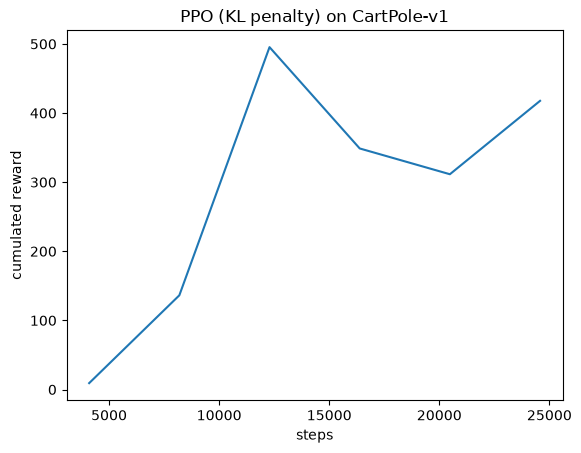

In [18]:
plt.plot([r.step for r in ppo.history], [r.mean for r in ppo.history])
plt.xlabel("steps")
plt.ylabel("cumulated reward")
plt.title("PPO (KL penalty) on CartPole-v1")
plt.show()

## Exercise

Compare the KL-penalty version with PPO-clip (`07-2`). Try a few values of
`beta`: too small barely constrains the update (like vanilla policy gradient,
unstable), too large freezes the policy.